In [1]:
import matplotlib.pyplot as plt
import pandas as pd

In [2]:
df = pd.read_csv("/scratch/hain/jf_count/kmer_counts.v1.tsv", sep="\t")
df["frac_unique"] = df["unique"] / df["total"]

In [12]:
df

,k,unique,distinct,total,frac_unique
0,15,177473864,547126837,3054785622,0.058097
1,17,1296194253,1683727573,3054831657,0.424310
2,19,2033632595,2184563225,3054831609,0.665710
3,21,2225376003,2319985692,3054831561,0.728477
4,23,2302872606,2385811672,3054831513,0.753846
5,25,2357453433,2435747918,3054831465,0.771713
6,27,2403229452,2478312532,3054831417,0.786698
7,29,2443237402,2515659529,3054831369,0.799795
8,31,2478848833,2548924586,3054831321,0.811452
9,41,2612010367,2672184991,3054831081,0.855042


In [3]:
def complete_kmer_coverage_probability(read_length, kmer_length):
    if read_length < kmer_length:
        return 0.0
    return (read_length - kmer_length + 1) / (
        read_length + kmer_length - 1
    )

In [5]:
complete_kmer_coverage_probability(150, 61)

0.42857142857142855

In [11]:
df[df["k"]==31]

,k,unique,distinct,total,frac_unique
8,31,2478848833,2548924586,3054831321,0.811452


In [8]:
df[df["k"]==61]

,k,unique,distinct,total,frac_unique
11,61,2746908367,2793029248,3054830601,0.899202


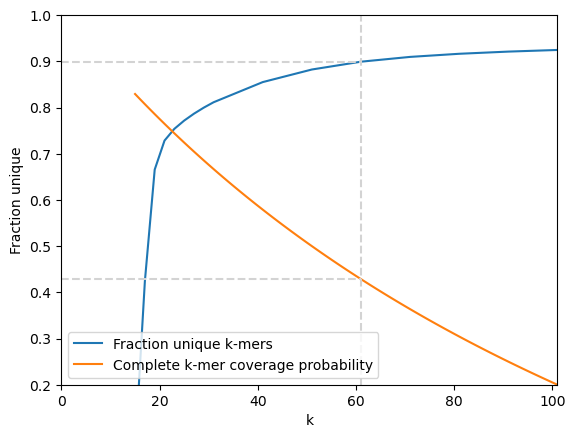

In [10]:
fig, ax = plt.subplots()

ax.plot(df["k"], df["frac_unique"], label="Fraction unique k-mers")

ax.plot(range(df["k"].min(), df["k"].max() + 1), [complete_kmer_coverage_probability(150, k) for k in range(df["k"].min(), df["k"].max() + 1)], label="Complete k-mer coverage probability")

ax.plot([61, 61], [0.15, 1], color="lightgray", linestyle="--")
ax.plot([0, 61], [complete_kmer_coverage_probability(150, 61), complete_kmer_coverage_probability(150, 61)], color="lightgray", linestyle="--")
ax.plot([0, 61], [df[df["k"] == 61]["frac_unique"].values[0]] * 2, color="lightgray", linestyle="--")

ax.set_xlabel("k")
ax.set_ylabel("Fraction unique")
ax.set_ylim(0.2, 1)
ax.set_xlim(0, 101)
ax.legend()
plt.savefig("plots/kmer_uniqueness.png")
plt.show()